# Diabetes — Leakage-controlled validation

Random Forest performance is evaluated using all eight features, three features, and five features. Median imputation is fitted on the training data only. Reported metrics include Accuracy, Precision, Recall, Specificity, F1 and ROC-AUC.

The five-feature configuration—Glucose, BMI, Age, Insulin and SkinThickness—is pre-specified for the XAI extension and is not selected using these test results.

Evaluation uses the same held-out observations as replication; it does not constitute validation on an additional independent cohort.

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

data_path = "../../data/diabetes/diabetes.csv"
df = pd.read_csv(data_path)
zero_invalid = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]


In [2]:
full_cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
             "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]

cols_3 = ["Glucose", "BMI", "Age"]
cols_5 = ["Glucose", "BMI", "Age", "Insulin", "SkinThickness"]

In [3]:
# Predictive branch: split before learning median-imputation values.
X = df[full_cols].astype(float).copy()
X[zero_invalid] = X[zero_invalid].replace(0, np.nan)
y = df["Outcome"].copy()

X_train_full, X_test_full, y_train, y_test = train_test_split(
    X, y, test_size=230, stratify=y, random_state=42
)

predictive_imputer = SimpleImputer(strategy="median")
X_train_full.loc[:, zero_invalid] = predictive_imputer.fit_transform(
    X_train_full[zero_invalid]
)
X_test_full.loc[:, zero_invalid] = predictive_imputer.transform(
    X_test_full[zero_invalid]
)

X_train_3 = X_train_full[cols_3]
X_test_3 = X_test_full[cols_3]

X_train_5 = X_train_full[cols_5]
X_test_5 = X_test_full[cols_5]

print(X_train_full.shape, X_test_full.shape)
print("\nTrain class counts:")
print(y_train.value_counts())
print("\nTest class counts:")
print(y_test.value_counts())


(538, 8) (230, 8)

Train class counts:
Outcome
0    350
1    188
Name: count, dtype: int64

Test class counts:
Outcome
0    150
1     80
Name: count, dtype: int64


In [4]:
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt

models = {
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42)
}


In [5]:
def compute_specificity(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fp)

def evaluate_model(model, X_train, X_test, y_train, y_test, model_name, dataset_name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    fpr, tpr, _ = roc_curve(y_test, y_score)

    return {
        "Dataset": dataset_name,
        "Model": model_name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "Specificity": compute_specificity(y_test, y_pred),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "AUC": roc_auc_score(y_test, y_score),
        "FPR": fpr,
        "TPR": tpr
    }


## Existing held-out metrics across Random Forest feature sets

In [6]:
results = []

dataset_map = {
    "Full (8 features)": (X_train_full, X_test_full),
    "3-factor": (X_train_3, X_test_3),
    "5-factor": (X_train_5, X_test_5)
}

for dataset_name, (Xtr, Xte) in dataset_map.items():
    for model_name, model in models.items():
        res = evaluate_model(model, Xtr, Xte, y_train, y_test, model_name, dataset_name)
        results.append(res)

results_df = pd.DataFrame([
    {k: v for k, v in r.items() if k not in ["FPR", "TPR"]}
    for r in results
])

display(results_df.round(4))

summary_table = results_df.copy()

,Dataset,Model,TN,FP,FN,TP,Accuracy,Precision,Recall,Specificity,F1,AUC
0,Full (8 features),Random Forest,127,23,37,43,0.7391,0.6515,0.5375,0.8467,0.5890,0.8242
1,3-factor,Random Forest,126,24,38,42,0.7304,0.6364,0.5250,0.8400,0.5753,0.7860
2,5-factor,Random Forest,125,25,32,48,0.7522,0.6575,0.6000,0.8333,0.6275,0.8155


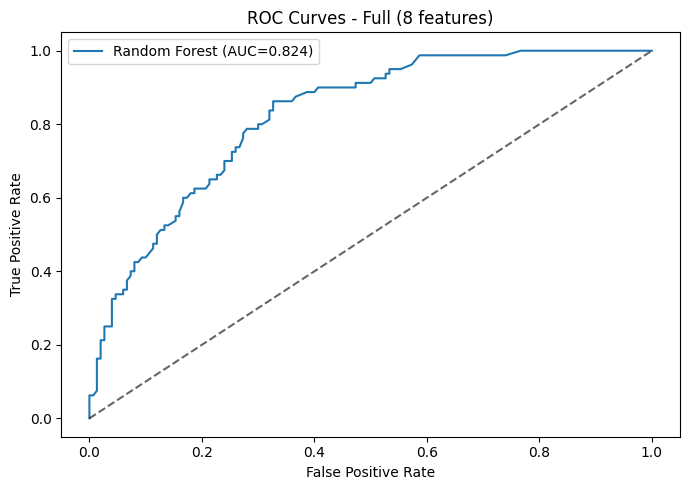

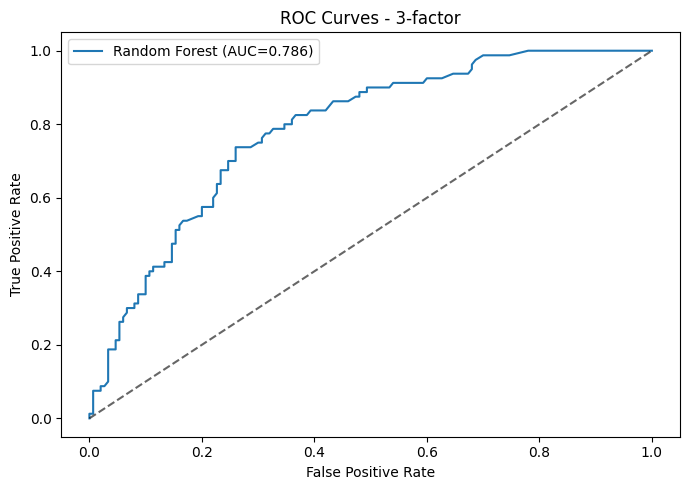

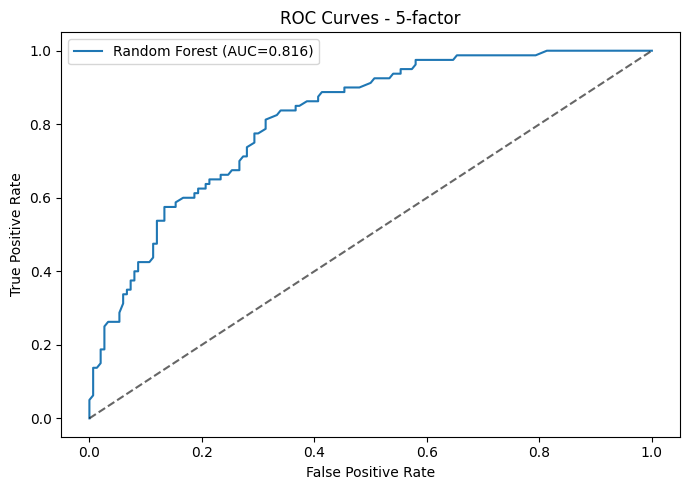

In [7]:
for dataset_name in dataset_map.keys():
    plt.figure(figsize=(7, 5))

    for r in results:
        if r["Dataset"] == dataset_name:
            plt.plot(r["FPR"], r["TPR"], label=f"{r['Model']} (AUC={r['AUC']:.3f})")

    plt.plot([0, 1], [0, 1], "k--", alpha=0.6)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curves - {dataset_name}")
    plt.legend()
    plt.tight_layout()
    plt.show()


## Pre-specified five-feature model handoff

In [8]:
best_model_name = "Random Forest"
best_dataset_name = "5-factor"

# The original loop evaluates the five-feature dataset last, so this
# estimator is already fitted on the pre-specified feature set.
best_model = models[best_model_name]
final_model = best_model
X_train_xai, X_test_xai = dataset_map[best_dataset_name]

validation_df = results_df.loc[
    (results_df["Model"] == best_model_name)
    & (results_df["Dataset"] == best_dataset_name)
].copy()
print("Pre-specified model and feature set:", best_model_name, best_dataset_name)
display(validation_df)


Pre-specified model and feature set: Random Forest 5-factor


,Dataset,Model,TN,FP,FN,TP,Accuracy,Precision,Recall,Specificity,F1,AUC
2,5-factor,Random Forest,125,25,32,48,0.752174,0.657534,0.6,0.833333,0.627451,0.815542
